<a href="https://colab.research.google.com/github/Oli-via123/AI-ML-Practice-and-Projects/blob/main/AI%20and%20ML%20Practice/Regression_Model/Regression_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Import Libraries

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import mean_squared_error

### Load the dataset

In [ ]:
# Load the data from sklearn datasets
housing = fetch_california_housing(as_frame=True)
df = housing.frame      # Converts to a Pandas DataFrame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.33,41.00,6.98,1.02,322.00,2.56,37.88,-122.23,4.53
1,8.30,21.00,6.24,0.97,2401.00,2.11,37.86,-122.22,3.58
2,7.26,52.00,8.29,1.07,496.00,2.80,37.85,-122.24,3.52
3,5.64,52.00,5.82,1.07,558.00,2.55,37.85,-122.25,3.41
4,3.85,52.00,6.28,1.08,565.00,2.18,37.85,-122.25,3.42


### Feature Engineering

In [ ]:
# Define features (X) and target variable (y)
X = df.drop(columns=["MedHouseVal"])    # Drop the target variable from the DataFrame so we'll be left with features
y = df["MedHouseVal"]      # Target/Dependent variable

In [ ]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.33,41.00,6.98,1.02,322.00,2.56,37.88,-122.23
1,8.30,21.00,6.24,0.97,2401.00,2.11,37.86,-122.22
2,7.26,52.00,8.29,1.07,496.00,2.80,37.85,-122.24
3,5.64,52.00,5.82,1.07,558.00,2.55,37.85,-122.25
4,3.85,52.00,6.28,1.08,565.00,2.18,37.85,-122.25


In [ ]:
y.head()

0   4.53
1   3.58
2   3.52
3   3.41
4   3.42
Name: MedHouseVal, dtype: float64

### Split dataset

In [ ]:
# split dataset into test and train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=234)

In [ ]:
print(f"X_train: {X_train.shape}")
print(f"X-test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (16512, 8)
X-test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


### Train Algorithm

In [ ]:
# initialize algorithm and train
regressor = RandomForestRegressor(n_estimators=100, random_state=234)
regressor.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

**Predict y_test**

In [ ]:
# Lets predict the test data of MedHouseVal
y_pred = regressor.predict(X_test)
y_pred

array([2.22216  , 4.6131757, 3.4052202, ..., 1.44594  , 1.90899  ,
       1.26388  ], shape=(4128,))

**Visual of the Actual vs Predicted**

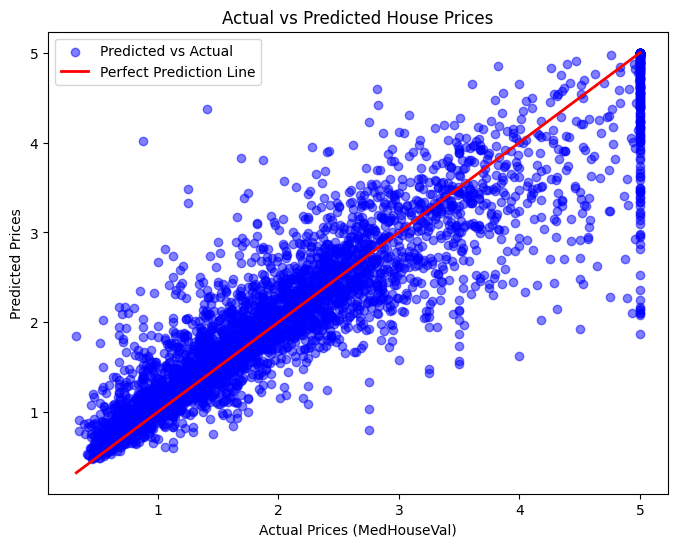

In [ ]:
# Let's see the scatter plot of Actual vs Predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color="blue", label="Predicted vs Actual")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r", lw=2, label="Perfect Prediction Line")
plt.xlabel("Actual Prices (MedHouseVal)")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()

**Compare the Outcome of Predicted Value to the Actual Value**

In [ ]:
# Compare the outcome of prediction and actual
df_result = pd.DataFrame({"Actual(y)": y_test, "Predicted(y)": y_pred})
df_result.head()

,Actual(y),Predicted(y)
10851,1.61,2.22
5486,5.00,4.61
8813,3.96,3.41
4600,1.18,1.87
13854,0.93,1.21


**Check the Difference Between Actual vs Predicted**

In [ ]:
diff = pd.DataFrame({"Difference": abs(y_test - y_pred)})   # Creates a DataFrame of difference between actual and predicted
df_result["Difference(residual)"] = diff["Difference"]    # Creates the differece btw actual vs predictes as a new column
df_result.head()


,Actual(y),Predicted(y),Difference(residual)
10851,1.61,2.22,0.61
5486,5.00,4.61,0.39
8813,3.96,3.41,0.56
4600,1.18,1.87,0.69
13854,0.93,1.21,0.27


In [ ]:
# Compare the difference btw actual vs predicted
#df_result["Difference"] = abs(df_result["Actual(y)"] - df_result["Predicted(y)"])
#df_result.head()

### Evaluate Model

In [ ]:
# Let's see the minimum and maximum value of the actual value
print("~"*40)
print("  Minimum and Maximum of Actual Value")
print("~"*40)
print(f"Minimum value for Actual(y): {df_result["Actual(y)"].min()}")
print(f"Maximum value for Actual(y): {df_result["Actual(y)"].max()}")
print()

# Let's see the minimum and maximum value of the predicted value
print("~"*42)
print("  Minimum and Maximum of Predicted Value")
print("~"*42)
print(f"Minimum value for Predicted(y): {df_result["Predicted(y)"].min()}")
print(f"Maximum value for Predicted(y): {df_result["Predicted(y)"].max()}")

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  Minimum and Maximum of Actual Value
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Minimum value for Actual(y): 0.325
Maximum value for Actual(y): 5.00001

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  Minimum and Maximum of Predicted Value
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
Minimum value for Predicted(y): 0.4815500000000002
Maximum value for Predicted(y): 5.000009999999989


In [ ]:
# Lets import the mean squared error from scikit learn
from sklearn.metrics import mean_squared_error

# Calculate the mean squared error
MSE = mean_squared_error(df_result["Actual(y)"], df_result["Predicted(y)"])
print(f"Mean Squared Error: {round(MSE, 3)}")

Mean Squared Error: 0.243


In [ ]:
# Calculating RMSE manually
import numpy as np

RMSE = np.sqrt(MSE)
print(f"Root Mean Squared Error: {round(RMSE, 3)}")

Root Mean Squared Error: 0.492


In [ ]:
# Let's use the RMSE to range our median house value (The house value is in thousand)
# Now, let's convert the predicted y to dollars, then add and subtract the RMSE in dollars to get the highest and lowest price range
# Then have them side by side with the actual median value

df_result["Predicted(y)"] = df_result["Predicted(y)"] * 100000  # Convert to dollars
df_result["Actual(y)"] = df_result["Actual(y)"] * 100000    # Convert to dollars

# Recalculating RMSE in dollars
rmse = np.sqrt(mean_squared_error(df_result["Actual(y)"], df_result["Predicted(y)"]))

# Let's create an error bound by independently adding and subtracting rmse from the predicted value
df_result["Highest_value"] = df_result["Predicted(y)"] + rmse   # Upper error bound
df_result["Lowest_value"] = df_result["Predicted(y)"] - rmse    # Lower error bound

pd.options.display.float_format = "{:.2f}".format
offer_value_range = df_result[["Predicted(y)", "Highest_value", "Lowest_value", "Actual(y)"]]
offer_value_range.head()

,Predicted(y),Highest_value,Lowest_value,Actual(y)
10851,222216.00,271460.42,172971.58,161000.00
5486,461317.57,510561.99,412073.15,500001.00
8813,340522.02,389766.44,291277.60,396400.00
4600,187312.00,236556.42,138067.58,118100.00
13854,120793.01,170037.43,71548.59,93400.00


In [ ]:
# Define a conditional filter that displays yes or no  if actual value is within the highest and lowest value
df_result["Within Range"] = (df_result["Actual(y)"] >= df_result["Lowest_value"]) & (df_result["Actual(y)"] <= df_result["Highest_value"])
df_result["Within Range"] = df_result["Within Range"].map({True: "yes", False: "no"})
offer_value_range = df_result[["Predicted(y)", "Highest_value", "Lowest_value", "Actual(y)", "Within Range"]]
offer_value_range.head(10)

,Predicted(y),Highest_value,Lowest_value,Actual(y),Within Range
10851,222216.00,271460.42,172971.58,161000.00,no
5486,461317.57,510561.99,412073.15,500001.00,yes
8813,340522.02,389766.44,291277.60,396400.00,no
4600,187312.00,236556.42,138067.58,118100.00,no
13854,120793.01,170037.43,71548.59,93400.00,yes
339,173967.00,223211.42,124722.58,80700.00,no
6944,163163.00,212407.42,113918.58,160700.00,yes
8322,103439.00,152683.42,54194.58,100800.00,yes
15108,160536.00,209780.42,111291.58,166100.00,yes
14660,180963.00,230207.42,131718.58,179100.00,yes


In [ ]:
# Let's check which actual values fall within the prediction interval
within_interval = (df_result["Actual(y)"] >= df_result["Lowest_value"]) & (df_result["Actual(y)"] <= df_result["Highest_value"])

# Calculate percentage
coverage = np.mean(within_interval) * 100

print(f"Coverage: {coverage:.2f}%")
print(f"Captured {np.sum(within_interval)} out of {len(y_test)} predictions")

Coverage: 79.87%
Captured 3297 out of 4128 predictions


In [ ]:
# Calculate the absolute errors
absolute_errors = np.abs(df_result["Actual(y)"] - df_result["Predicted(y)"])

# Calculate the mean of the absolute errors
MAE = np.mean(absolute_errors)

print(f"Mean Absolute Error: {round(MAE, 2)} dollars")

Mean Absolute Error: 31965.19 dollars


In [ ]:
# lets use scikit learn
from sklearn.metrics import mean_absolute_error

MAE = mean_absolute_error(df_result["Actual(y)"], df_result["Predicted(y)"])
print(f"Mean Absolute Error: {round(MAE, 2)} dollars")

Mean Absolute Error: 31965.19 dollars


In [ ]:
# Calculating our R-squared manually

residuals = df_result["Actual(y)"] - df_result["Predicted(y)"]

SSR = np.sum(residuals**2)
SST = np.sum((df_result["Actual(y)"] - np.mean(df_result["Actual(y)"]))**2)


unexplainable_variations= SSR / SST
R_squared = 1 - unexplainable_variations
print(f"R-squared: {round(R_squared, 3)}")

R-squared: 0.817


In [ ]:
# Lets calculate R-squared using Scikit learn
from sklearn.metrics import r2_score

R_squared = r2_score(df_result["Actual(y)"],df_result["Predicted(y)"])
print(f"R-squared: {round(R_squared, 3)}")

R-squared: 0.817
